In [1]:
import pandas as pd
import math
from sys import float_info
import os
from scipy.stats import spearmanr, linregress, ttest_rel
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def lk_to_dict(lk): 
    lk_arr = lk.strip("[]").split("], [")
    dict = {}
    for l in lk_arr: 
        key, val = l.split(", ")
        dict[int(key)] = float(val)
    return(dict)
def loss_from_df(df): 
    correct_labels = df["correct"]
    answer = df["answer"]
    likelihoods = df["likelihoods"]
    eval_loss = 0
    count = 0
    curr_iter = -1
    prob = 1
    losses = []
    tokens = []
    curr_tokens = []
    for label, iter, lk in zip(correct_labels, answer, likelihoods):  
        lbl, atkn = label.strip("[]").split(",")
        lk_dict = lk_to_dict(lk)
        if curr_iter == -1: 
            curr_iter = iter
        if curr_iter == iter : 
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob *= p
            curr_tokens.append([lbl, atkn])
        else: 
            if prob == 0: 
                    eval_loss += -math.log(float_info.min)
                    losses.append(-math.log(float_info.min))
            else:
                    eval_loss += -math.log(prob)
                    losses.append(-math.log(prob))
            tokens.append(curr_tokens)
            curr_tokens = [[lbl, atkn]]
            count += 1
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob = p
            curr_iter = iter
    if prob == 0: 
        eval_loss += -math.log(float_info.min)
        losses.append(-math.log(float_info.min))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    elif prob != 1:
        eval_loss += -math.log(prob)
        losses.append(-math.log(prob))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    count += 1
    tokens.append(curr_tokens)
    curr_tokens = []
    return(losses, tokens)


In [3]:
def get_values(study, model, variant = "whole_runs"):
    result_dict = {"study": [],"model": [],  "participant": [], "trial_num": [], "tokens": [], "loss": [] }
    for trial_file in os.listdir(f"full_results/{model}/{study}_{variant}"):
        trial_df = pd.read_csv(f"full_results/{model}/{study}_{variant}/{trial_file}")
        losses, tokens = loss_from_df(trial_df)
        part = trial_file.split("_")[-1].split(".")[0]
        i = 0
        for loss, token_arr in (zip(losses,tokens)):
            result_dict["loss"].append(loss)
            result_dict["participant"].append(part)
            result_dict["tokens"].append(token_arr)
            result_dict["study"].append(study)
            result_dict["model"].append(model)
            i+= 1
            result_dict["trial_num"].append(i)
    return(result_dict)

In [ ]:
studies = ["Ajami18", "Bauer19", "Börstler16", "Buse10", "Gopstein17a", "Gopstein17b", "Medeiros19", "Siegmund17", "Peitek18"]
result_dict = {"study": [], "model": [], "participant": [], "trial_num": [], "tokens": [], "loss": [] }
models = ["Centaur", "Llama"]
for study in studies:
    for model in models: 
        res_dict = get_values(study, model, "no_snippets_no_desc")
        for key in result_dict: 
            result_dict[key] = result_dict[key] + res_dict[key]
result_df = pd.DataFrame(result_dict)

In [5]:
def get_correlations(study, df):
    correlations = {}
    linregs = {}
    for model in ["Centaur", "Llama"]:
        model_data = df[df["model"] == model]
        study_data = model_data[model_data["study"] == study]
        trial_nums = []
        losses = []
        for i in range(len(study_data)):
            losses.append(study_data["loss"].iloc[i])
            trial_nums.append(study_data["trial_num"].iloc[i])
        correlation = spearmanr(losses, trial_nums)
        print(f"{model} correlation: {correlation}")
        correlations[model] = correlation
        linreg = linregress(trial_nums, losses)
        linregs[model] = linreg
        plt.plot(trial_nums, losses, "+")
        plt.title(f"trial-loss correlation {model} {study}")
        plt.show()
        plt.close()
    return correlations, linregs


In [6]:
def get_losses(study, df, model): 
    model_data = df[df["model"] == model]
    study_data = model_data[model_data["study"] == study]
    losses = []
    ids = []
    for i in range(len(study_data)):
        losses.append(study_data["loss"].iloc[i])
        ids.append([study_data["participant"].iloc[i], study_data["trial_num"].iloc[i]])
    return losses, ids

def evaluate_study(study, df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses, ids = get_losses(study, df, model)
        ids_arrs.append(ids)
        losses_dict[model] = losses
        res_dict[f"{model}_mean"] = np.mean(losses)
        res_dict[f"{model}_std"] = np.std(losses)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = study
    return(res_dict)
def eval_all(df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses_all = []
        ids_all = []
        for study in studies:
            losses, ids = get_losses(study, df, model)
            losses_all += losses
            ids_all+= ids
        ids_arrs.append(ids_all)
        print(len(losses_all))
        losses_dict[model] = losses_all
        res_dict[f"{model}_mean"] = np.mean(losses_all)
        res_dict[f"{model}_std"] = np.std(losses_all)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses_all)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = "overall"
    return(res_dict)

In [7]:
all_res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
for study in studies: 
    study_res_dict = evaluate_study(study, result_df)
    for key in all_res_dict:
        all_res_dict[key].append(study_res_dict[key])
study_res_dict = eval_all(result_df)
for key in study_res_dict:
    all_res_dict[key].append(study_res_dict[key])
all_res_df = pd.DataFrame(all_res_dict)
all_res_df.to_csv("results/results_RQ2_no_snippets_no_desc.csv", index=False)
result_df.to_csv("results/data_RQ2_no_snippets_no_desc.csv", index=False)

25554
25554


Ajami18: 2067 Trials
Centaur mean: 3.0283077811999486, STD: 2.438032857198232
Llama mean: 3.1624011834163492, STD: 2.778374129851746
T-test statistic: -10.260981711711148, p-value: 3.963030480227028e-24, cohen's d: -0.22569330445731103


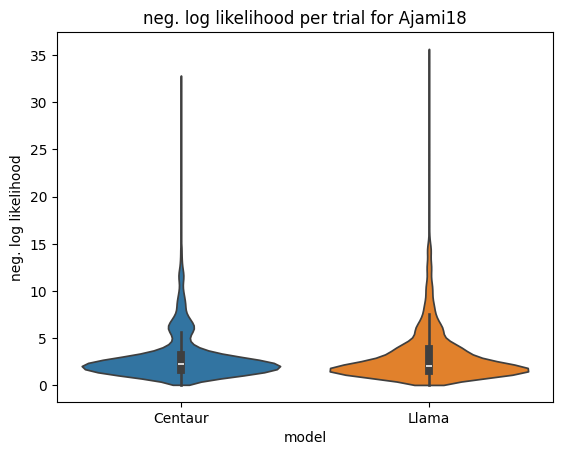

Bauer19: 88 Trials
Centaur mean: 9.653272362185271, STD: 9.641033054456871
Llama mean: 10.940485171023896, STD: 11.102026065306863
T-test statistic: -7.084141508828682, p-value: 3.4470577494844353e-10, cohen's d: -0.755172022223395


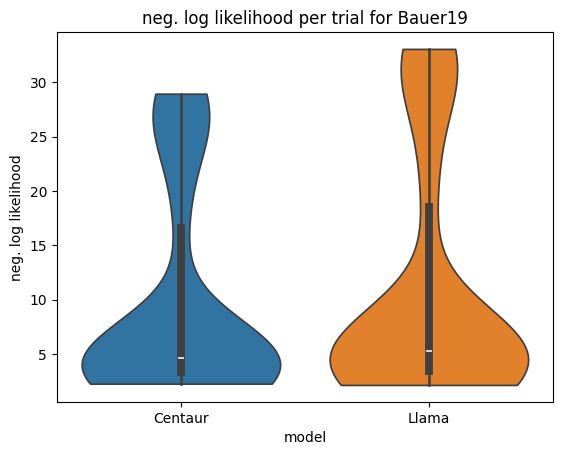

Börstler16: 2598 Trials
Centaur mean: 10.797544898318533, STD: 14.66019852534606
Llama mean: 11.051935392107838, STD: 14.581457155406529
T-test statistic: -5.396241292466149, p-value: 7.420156378728058e-08, cohen's d: -0.10586972561400439


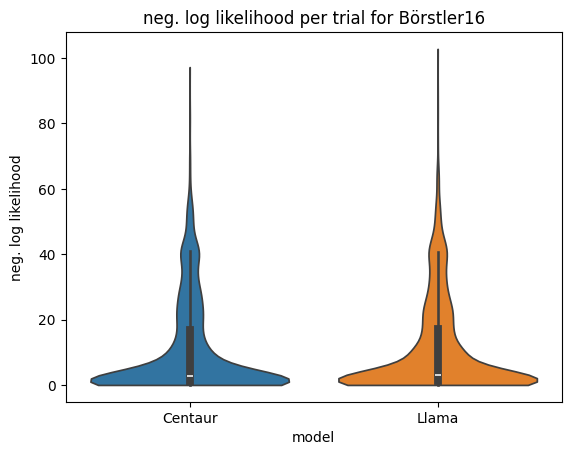

Buse10: 12100 Trials
Centaur mean: 1.5421463763457213, STD: 0.6613754383306328
Llama mean: 1.550175989413828, STD: 0.6086054831125954
T-test statistic: -2.5881703421024715, p-value: 0.009660261315912858, cohen's d: -0.02352882129184065


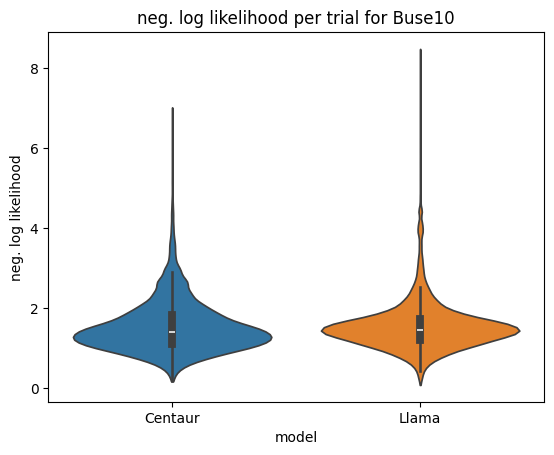

Gopstein17a: 6069 Trials
Centaur mean: 4.502877412325885, STD: 2.8932496569561454
Llama mean: 4.848715556593364, STD: 3.2974587741296
T-test statistic: -29.080562363051506, p-value: 3.5370151808263665e-174, cohen's d: -0.3732881744553708


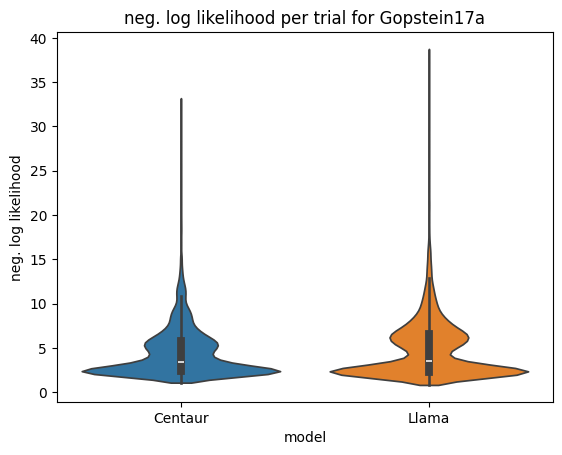

Gopstein17b: 498 Trials
Centaur mean: 9.5562101004499, STD: 8.451082788184653
Llama mean: 10.18040092268102, STD: 9.290107400618957
T-test statistic: -7.955759896940856, p-value: 1.2124283522274673e-14, cohen's d: -0.3565061255374551


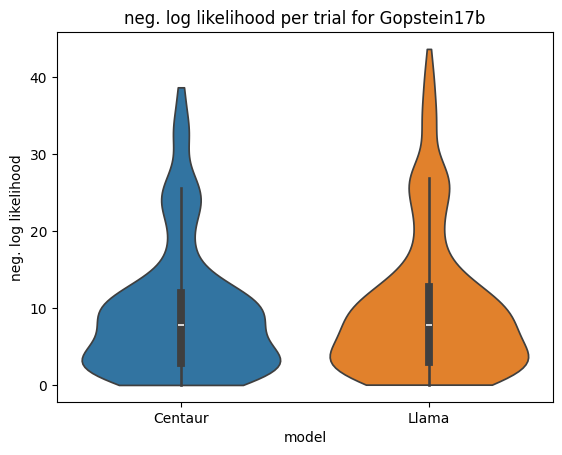

Medeiros19: 1164 Trials
Centaur mean: 1.9884361073025212, STD: 0.8664188511164196
Llama mean: 2.1007844003892333, STD: 0.896586723954296
T-test statistic: -6.825032494804673, p-value: 1.4118119029601768e-11, cohen's d: -0.20004524521538006


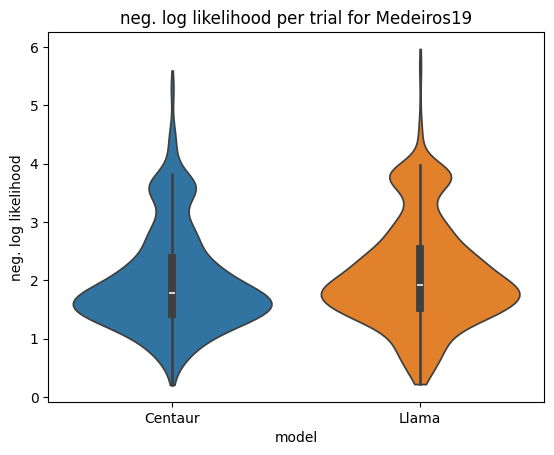

Peitek17: 420 Trials
Centaur mean: 0.7913145101132003, STD: 1.6035540257819783
Llama mean: 0.9871426661871102, STD: 2.178235544241892
T-test statistic: -5.665903115649743, p-value: 2.7231441279083032e-08, cohen's d: -0.27646776319409533


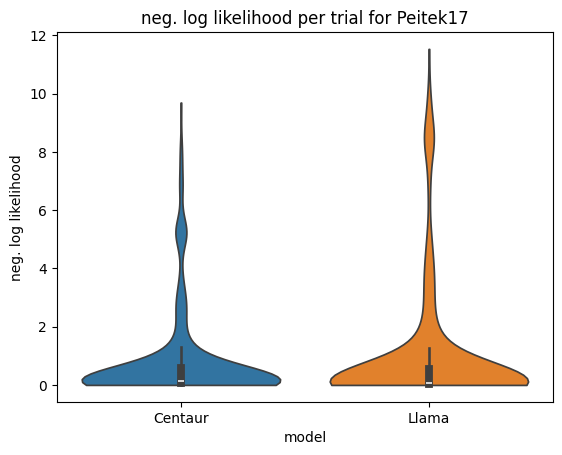

Peitek18b: 550 Trials
Centaur mean: 1.0315727563055184, STD: 1.76783649163001
Llama mean: 1.268120204706147, STD: 2.383760237891219
T-test statistic: -6.741188924795603, p-value: 3.9852170208223574e-11, cohen's d: -0.28744526157098593


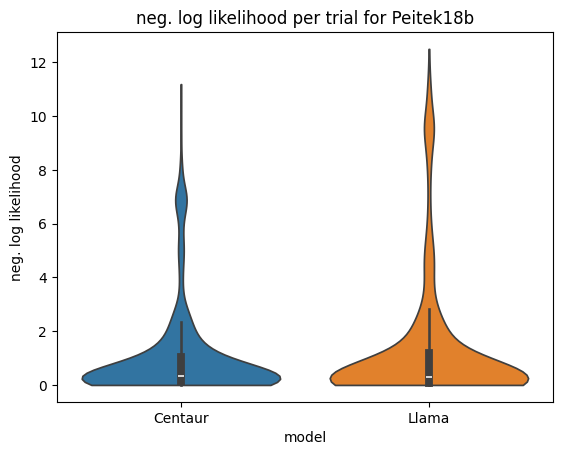

overall: 25554 Trials
Centaur mean: 3.4876029324478726, STD: 5.921908228716193
Llama mean: 3.640274595314843, STD: 6.05989328741798
T-test statistic: -24.286473880232926, p-value: 7.872064775695106e-129, cohen's d: -0.15192702005566966


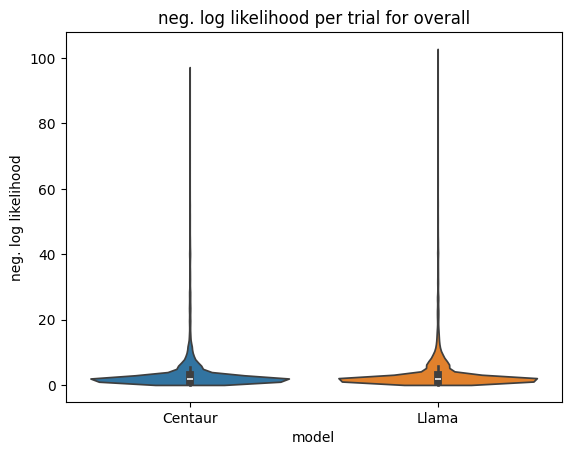

In [8]:
#TODO Violinplots & Eval
import seaborn as sns

import seaborn as sns
variant = "RQ2_no_snippets_no_desc"
for study in studies: 
    study_data_df = result_df[result_df["study"]==study]
    study_result_df = all_res_df[all_res_df["study"]==study]
    print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
    print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
    print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
    print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
    sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
    plt.ylabel("neg. log likelihood")
    plt.title(f"neg. log likelihood per trial for {study}")
    plt.savefig(f"images/{study}_violin_{variant}.png")
    plt.show()
    plt.close()
study = "overall"
study_data_df = result_df
study_result_df = all_res_df[all_res_df["study"]==study]
print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
plt.ylabel("neg. log likelihood")
plt.title(f"neg. log likelihood per trial for {study}")
plt.savefig(f"images/{study}_violin_{variant}.png")
plt.show()
plt.close()